# Bean Leaf Disease Classification Using a Custom CNN

Name: Pritha Biswas Prama  
Student ID: 22-46161-1

Git link:
https://github.com/pritha-biswas-prama/CNN 

## Objective

The objective of this project is to build and train a custom convolutional
neural network to classify bean-leaf images into three categories:
angular leaf spot, bean rust, and healthy.

The project includes dataset exploration, preprocessing, training,
validation, test evaluation, and saving the trained model. 

## Dataset

Dataset: Beans  
Source: Makerere AI Lab, available through Hugging Face  
Link: https://huggingface.co/datasets/AI-Lab-Makerere/beans

The dataset provides three predefined splits:
- Training: 1,034 images
- Validation: 133 images
- Test: 128 images

The original splits were preserved. Training data was used to
learn model parameters, validation data was used to select the
checkpoint, and test data was reserved for final evaluation.

In [36]:
#cell 2
%pip install -q datasets pillow torchinfo

Note: you may need to restart the kernel to use updated packages.


In [37]:
#cell 3
#import libraries and set the environment
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

from datasets import load_dataset as hf_load_dataset

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch version:", torch.__version__)
print("Device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


cell 4   
## Load and Explore the Dataset

The Beans dataset is loaded directly from Hugging Face.

Its original training, validation, and test splits are preserved.
Class names are read from the dataset metadata to keep the label
mapping consistent throughout the project.

In [38]:
#cell 5
#load the dataset
dataset = hf_load_dataset("AI-Lab-Makerere/beans")

class_names = dataset["train"].features["labels"].names
num_classes = len(class_names)

print(dataset)
print("\nClass names:", class_names)
print("Number of classes:", num_classes)

print("\nClass mapping:")
for index, name in enumerate(class_names):
    print(f"{index}: {name}")

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})

Class names: ['angular_leaf_spot', 'bean_rust', 'healthy']
Number of classes: 3

Class mapping:
0: angular_leaf_spot
1: bean_rust
2: healthy


In [39]:
#cell 6 
#split sizes and class counts
split_summary = pd.DataFrame({
    "Split": ["train", "validation", "test"],
    "Number of images": [
        len(dataset["train"]),
        len(dataset["validation"]),
        len(dataset["test"])
    ]
})

print("Dataset split sizes:")
display(split_summary)

class_counts = pd.DataFrame({
    split: np.bincount(
        dataset[split]["labels"],
        minlength=num_classes
    )
    for split in ["train", "validation", "test"]
}, index=class_names)

class_counts.index.name = "Class"

print("\nImages per class:")
display(class_counts)

print("\nTotal images:", split_summary["Number of images"].sum())

assert num_classes == 3
assert len(dataset["train"]) == 1034
assert len(dataset["validation"]) == 133
assert len(dataset["test"]) == 128

print("\nDataset size checks passed.")

Dataset split sizes:


,Split,Number of images
0,train,1034
1,validation,133
2,test,128



Images per class:


,train,validation,test
Class,,,
angular_leaf_spot,345,44,43
bean_rust,348,45,43
healthy,341,44,42



Total images: 1295

Dataset size checks passed.


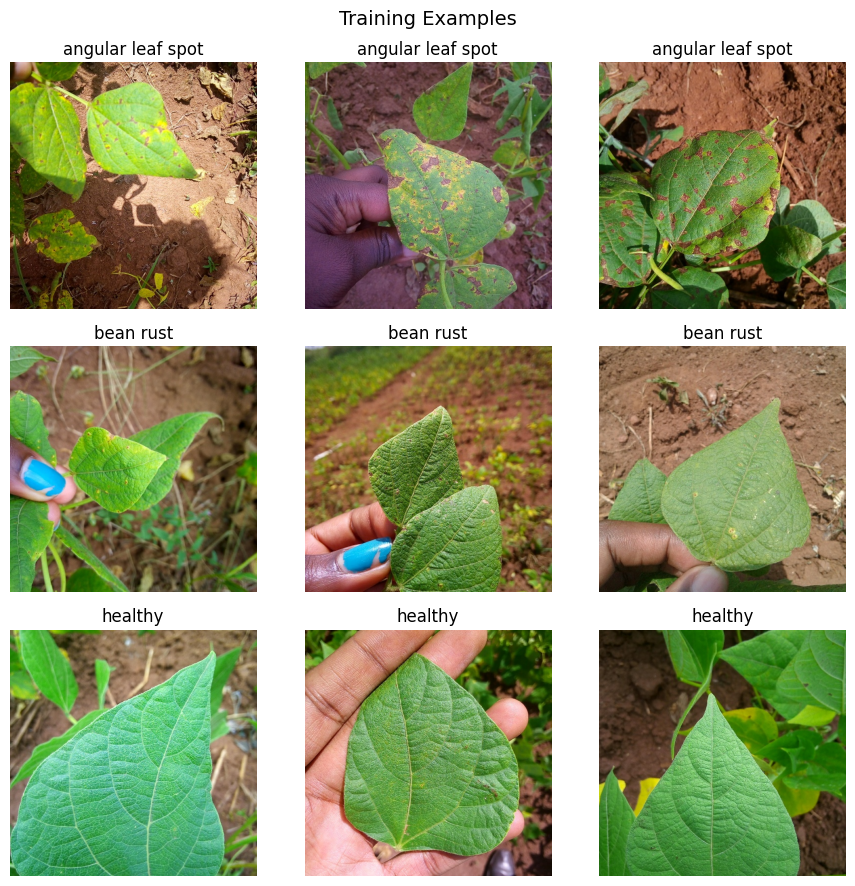

In [40]:
#cell 7
#display training examples
train_labels = np.array(dataset["train"]["labels"])

fig, axes = plt.subplots(
    num_classes, 3,
    figsize=(9, 3 * num_classes)
)

for class_index, class_name in enumerate(class_names):
    matching_indices = np.where(train_labels == class_index)[0][:3]

    for column, image_index in enumerate(matching_indices):
        sample = dataset["train"][int(image_index)]
        image = sample["image"].convert("RGB")

        axes[class_index, column].imshow(image)
        axes[class_index, column].set_title(
            class_name.replace("_", " ")
        )
        axes[class_index, column].axis("off")

plt.suptitle("Training Examples", fontsize=14)
plt.tight_layout()
plt.show()

cell 8
## Preprocessing and Data Augmentation

All images are converted to RGB and resized to 128 × 128 pixels.

Training preprocessing:
- Resize to a consistent input size.
- Random horizontal flipping.
- Random rotation of up to 15 degrees.
- Modest brightness, contrast, and saturation changes.
- Convert images to tensors with pixel values in the range [0, 1].

Validation and test preprocessing:
- Resize to the same input size.
- Convert images to tensors.
- Do not apply random augmentation.

Augmentation is applied only to training images. The same deterministic
preprocessing is used for validation and testing.

The initial batch size is 32, following the instructor's example.

In [41]:
# cell 9
#define transforms and settings
size = 128
batch_size = 32

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

print("Image size:", (size, size))
print("Batch size:", batch_size)

Image size: (128, 128)
Batch size: 32


In [42]:
#cell 10:  create a small dataset wrapper
class BeansDataset(Dataset):
    def __init__(self, data, transform=None):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample = self.data[index]

        image = sample["image"].convert("RGB")
        label = int(sample["labels"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [43]:
#cell 11: create the three data loaders
train_data = BeansDataset(
    dataset["train"],
    transform=train_transform
)

val_data = BeansDataset(
    dataset["validation"],
    transform=val_transform
)

test_data = BeansDataset(
    dataset["test"],
    transform=val_transform
)

loader_generator = torch.Generator().manual_seed(SEED)

trn_dl = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=(device == "cuda"),
    generator=loader_generator
)

val_dl = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(device == "cuda")
)

test_dl = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(device == "cuda")
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

print("\nTraining batches:", len(trn_dl))
print("Validation batches:", len(val_dl))
print("Test batches:", len(test_dl))

Training images: 1034
Validation images: 133
Test images: 128

Training batches: 33
Validation batches: 5
Test batches: 4


In [44]:
#cell 12: verify one batch
images, labels = next(iter(trn_dl))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print(
    "Pixel range:",
    round(images.min().item(), 4),
    "to",
    round(images.max().item(), 4)
)

print("Labels in this batch:", labels.unique().tolist())

assert images.shape == (batch_size, 3, size, size)
assert labels.shape == (batch_size,)
assert images.dtype == torch.float32
assert labels.dtype == torch.int64
assert images.min().item() >= 0.0
assert images.max().item() <= 1.0
assert labels.min().item() >= 0
assert labels.max().item() < num_classes

print("\nAll batch checks passed.")

Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Pixel range: 0.0 to 1.0
Labels in this batch: [0, 1, 2]

All batch checks passed.


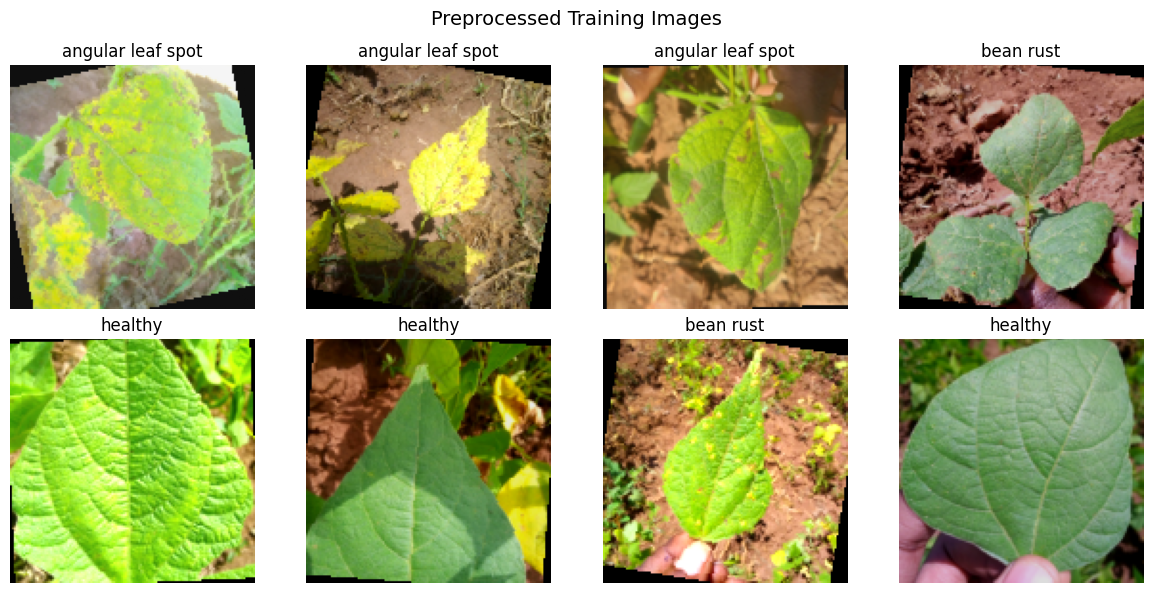

In [45]:
#cell 13:  
#display a preprocessed batch
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for index, ax in enumerate(axes.flat):
    image = images[index].permute(1, 2, 0).numpy()
    label = labels[index].item()

    ax.imshow(image)
    ax.set_title(class_names[label].replace("_", " "))
    ax.axis("off")

plt.suptitle("Preprocessed Training Images", fontsize=14)
plt.tight_layout()
plt.show()

cell 14
## Custom CNN Architecture

The model is a custom CNN trained from scratch.

It contains three convolution blocks with 32, 64, and 128 output channels.
Each block uses a 3 × 3 convolution, ReLU activation, and max pooling.

The increasing channel counts allow successive layers to learn more
feature maps, while max pooling reduces spatial dimensions.

Adaptive average pooling produces 4 × 4 feature maps before classification.
The classifier contains a 128-unit hidden layer, dropout, and an output
layer with one logit per class.

Dropout is included as a regularization choice. Its effectiveness will
be assessed using the training and validation curves.

No pretrained model or pretrained weights are used.

In [46]:
#cell 15  
#model and training settings
from torch.optim import Adam
from torchinfo import summary
from pathlib import Path

learning_rate = 1e-3
epoch_number = 20
weight_decay = 1e-4
dropout_rate = 0.3

output_dir = Path("/kaggle/working")
model_path = output_dir / "best_model.pth"

def get_model():
    model = nn.Sequential(
        # Feature extraction
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.AdaptiveAvgPool2d((4, 4)),

        # Classification
        nn.Flatten(),
        nn.Linear(128 * 4 * 4, 128),
        nn.ReLU(),
        nn.Dropout(dropout_rate),
        nn.Linear(128, num_classes)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()

    optimizer = Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    return model, loss_fn, optimizer

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model, loss_fn, optimizer = get_model()

summary(
    model,
    input_size=(1, 3, size, size),
    col_names=["input_size", "output_size", "num_params"],
    mode="eval"
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [1, 3, 128, 128]          [1, 3]                    --
├─Conv2d: 1-1                            [1, 3, 128, 128]          [1, 32, 128, 128]         896
├─ReLU: 1-2                              [1, 32, 128, 128]         [1, 32, 128, 128]         --
├─MaxPool2d: 1-3                         [1, 32, 128, 128]         [1, 32, 64, 64]           --
├─Conv2d: 1-4                            [1, 32, 64, 64]           [1, 64, 64, 64]           18,496
├─ReLU: 1-5                              [1, 64, 64, 64]           [1, 64, 64, 64]           --
├─MaxPool2d: 1-6                         [1, 64, 64, 64]           [1, 64, 32, 32]           --
├─Conv2d: 1-7                            [1, 64, 32, 32]           [1, 128, 32, 32]          73,856
├─ReLU: 1-8                              [1, 128, 32, 32]          [1, 128, 32, 32]          --
├─MaxPool2d: 1-9          

In [47]:
#cell 16
#check the model before training
images, labels = next(iter(trn_dl))

model.eval()

with torch.no_grad():
    logits = model(images.to(device))
    check_loss = loss_fn(logits, labels.to(device))

print("Input shape:", images.shape)
print("Output shape:", logits.shape)
print("Initial loss:", round(check_loss.item(), 4))

assert logits.shape == (batch_size, num_classes)
assert torch.isfinite(check_loss).item()

print("Model checks passed.")

Input shape: torch.Size([32, 3, 128, 128])
Output shape: torch.Size([32, 3])
Initial loss: 1.1035
Model checks passed.


cell 17  
## Training Protocol

The model is trained using cross-entropy loss and the Adam optimizer.

Initial hyperparameters:
- Image size: 128 × 128
- Batch size: 32
- Epochs: 20
- Learning rate: 0.001
- Weight decay: 0.0001
- Dropout probability: 0.3

Adam is selected as the initial optimizer, following the instructor's
CNN example. The learning rate and batch size also follow that example.

Weight decay and dropout are included as regularization choices.
These settings are a starting configuration, not the result of an
exhaustive hyperparameter search.

Training and validation metrics are recorded after every epoch.
The checkpoint with the lowest validation loss is saved.

The test set is not used during training or checkpoint selection.

In [48]:
#cell 18  
#training and evaluation functions
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        prediction = model(x)
        batch_loss = loss_fn(prediction, y)

        batch_loss.backward()
        optimizer.step()

        total_loss += batch_loss.item() * x.size(0)
        total_correct += (prediction.argmax(dim=1) == y).sum().item()
        total_samples += x.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        prediction = model(x)
        batch_loss = loss_fn(prediction, y)

        total_loss += batch_loss.item() * x.size(0)
        total_correct += (prediction.argmax(dim=1) == y).sum().item()
        total_samples += x.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [49]:
#cell 19
import time

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

random.seed(SEED)
np.random.seed(SEED)
loader_generator.manual_seed(SEED)

model, loss_fn, optimizer = get_model()

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

best_val_loss = float("inf")
best_epoch = 0

start_time = time.time()

for epoch in range(epoch_number):
    train_loss, train_acc = train_one_epoch(
        trn_dl, model, loss_fn, optimizer
    )

    val_loss, val_acc = validation(
        val_dl, model, loss_fn
    )

    if not np.isfinite(train_loss) or not np.isfinite(val_loss):
        raise RuntimeError("Non-finite loss detected. Stop and inspect the run.")

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    checkpoint_message = ""

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        torch.save(model.state_dict(), model_path)
        checkpoint_message = " | Saved best model"

    print(
        f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {train_loss:.4f}"
        f" | Train Accuracy: {train_acc * 100:.2f}%"
        f" | Val Loss: {val_loss:.4f}"
        f" | Val Accuracy: {val_acc * 100:.2f}%"
        f"{checkpoint_message}"
    )

training_minutes = (time.time() - start_time) / 60

history = pd.DataFrame({
    "epoch": range(1, epoch_number + 1),
    "train_loss": train_losses,
    "val_loss": val_losses,
    "train_accuracy": train_accuracies,
    "val_accuracy": val_accuracies
})

history.to_csv(output_dir / "training_history.csv", index=False)

print(f"\nTraining time: {training_minutes:.2f} minutes")
print("Best checkpoint epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print("Checkpoint exists:", model_path.exists())

Epoch [1/20] | Train Loss: 1.0936 | Train Accuracy: 35.40% | Val Loss: 1.0279 | Val Accuracy: 46.62% | Saved best model
Epoch [2/20] | Train Loss: 0.9815 | Train Accuracy: 48.94% | Val Loss: 0.8727 | Val Accuracy: 59.40% | Saved best model
Epoch [3/20] | Train Loss: 0.9099 | Train Accuracy: 55.71% | Val Loss: 0.8096 | Val Accuracy: 61.65% | Saved best model
Epoch [4/20] | Train Loss: 0.8586 | Train Accuracy: 58.80% | Val Loss: 0.7792 | Val Accuracy: 62.41% | Saved best model
Epoch [5/20] | Train Loss: 0.7936 | Train Accuracy: 64.31% | Val Loss: 0.6282 | Val Accuracy: 70.68% | Saved best model
Epoch [6/20] | Train Loss: 0.7189 | Train Accuracy: 69.05% | Val Loss: 0.6731 | Val Accuracy: 63.91%
Epoch [7/20] | Train Loss: 0.7255 | Train Accuracy: 69.63% | Val Loss: 0.6496 | Val Accuracy: 70.68%
Epoch [8/20] | Train Loss: 0.7028 | Train Accuracy: 70.02% | Val Loss: 0.5945 | Val Accuracy: 73.68% | Saved best model
Epoch [9/20] | Train Loss: 0.6837 | Train Accuracy: 70.79% | Val Loss: 0.5800 

cell 20
## Training and Validation Curves

The following plots show training and validation loss and accuracy
throughout training.

The dashed line marks the checkpoint selected using validation loss.
Training metrics are measured with training augmentation and dropout
active, while validation uses evaluation mode without random augmentation.
Therefore, training and validation conditions are not identical.

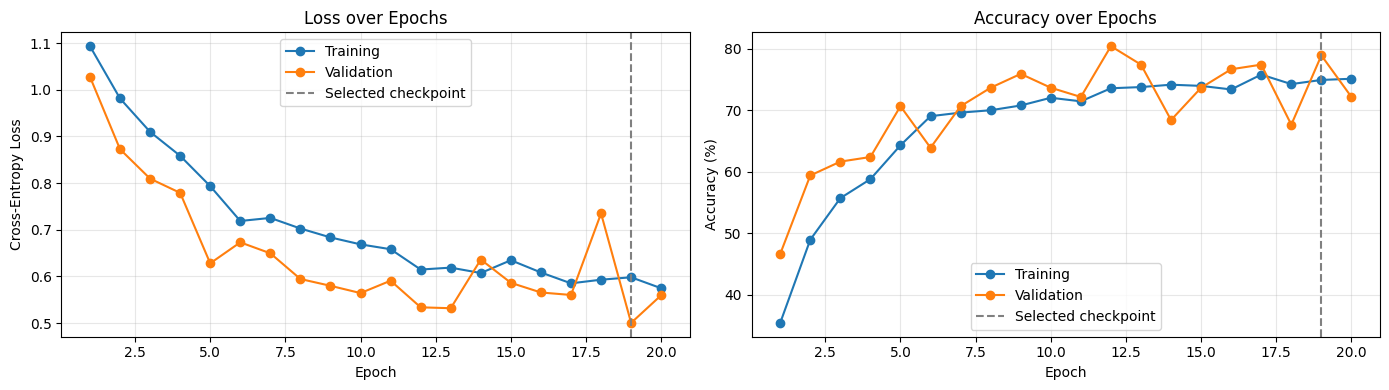

In [50]:
#cell 21
#plot and save the curves
epochs = history["epoch"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(
    epochs, history["train_loss"], marker="o", label="Training"
)
axes[0].plot(
    epochs, history["val_loss"], marker="o", label="Validation"
)
axes[0].set_title("Loss over Epochs")
axes[0].set_ylabel("Cross-Entropy Loss")

axes[1].plot(
    epochs, history["train_accuracy"] * 100,
    marker="o", label="Training"
)
axes[1].plot(
    epochs, history["val_accuracy"] * 100,
    marker="o", label="Validation"
)
axes[1].set_title("Accuracy over Epochs")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.axvline(
        best_epoch, color="gray", linestyle="--",
        label="Selected checkpoint"
    )
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(output_dir / "training_curves.png", dpi=150)
plt.show()

cell 22
## Test Evaluation

The checkpoint with the lowest validation loss is loaded into a fresh
instance of the same CNN architecture.

The held-out test set is evaluated using test loss, accuracy, per-class
precision, recall, F1-score, and a confusion matrix.

Test results are used for final reporting, not checkpoint selection.

In [51]:
#cell 23 
#load weights and check restoration
saved_model = get_model()[0]

saved_model.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

saved_model.eval()

test_loss, test_acc = validation(
    test_dl, saved_model, loss_fn
)

model_size_mb = model_path.stat().st_size / (1024 ** 2)

print("Loaded checkpoint epoch:", best_epoch)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Saved weights size: {model_size_mb:.2f} MiB")

Loaded checkpoint epoch: 19
Test Loss: 0.4676
Test Accuracy: 84.38%
Saved weights size: 1.36 MiB


                   precision    recall  f1-score   support

angular_leaf_spot     0.7755    0.8837    0.8261        43
        bean_rust     0.8378    0.7209    0.7750        43
          healthy     0.9286    0.9286    0.9286        42

         accuracy                         0.8438       128
        macro avg     0.8473    0.8444    0.8432       128
     weighted avg     0.8467    0.8438    0.8426       128



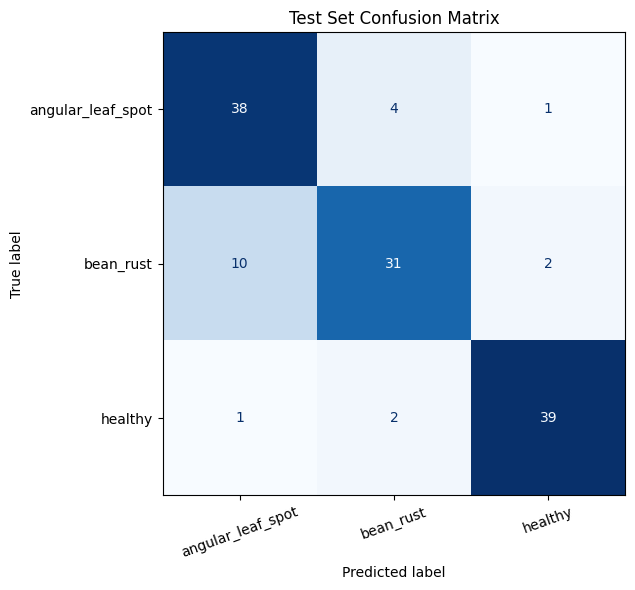

In [52]:
#cell 24
#classification report and confusion matrix
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

true_labels = []
predicted_labels = []

saved_model.eval()

with torch.no_grad():
    for x, y in test_dl:
        logits = saved_model(x.to(device))
        predictions = logits.argmax(dim=1)

        true_labels.extend(y.tolist())
        predicted_labels.extend(predictions.cpu().tolist())

label_indices = list(range(num_classes))

print(classification_report(
    true_labels,
    predicted_labels,
    labels=label_indices,
    target_names=class_names,
    digits=4,
    zero_division=0
))

report = classification_report(
    true_labels,
    predicted_labels,
    labels=label_indices,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    output_dir / "classification_report.csv"
)

cm = confusion_matrix(
    true_labels, predicted_labels, labels=label_indices
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Test Set Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix.png", dpi=150)
plt.show()

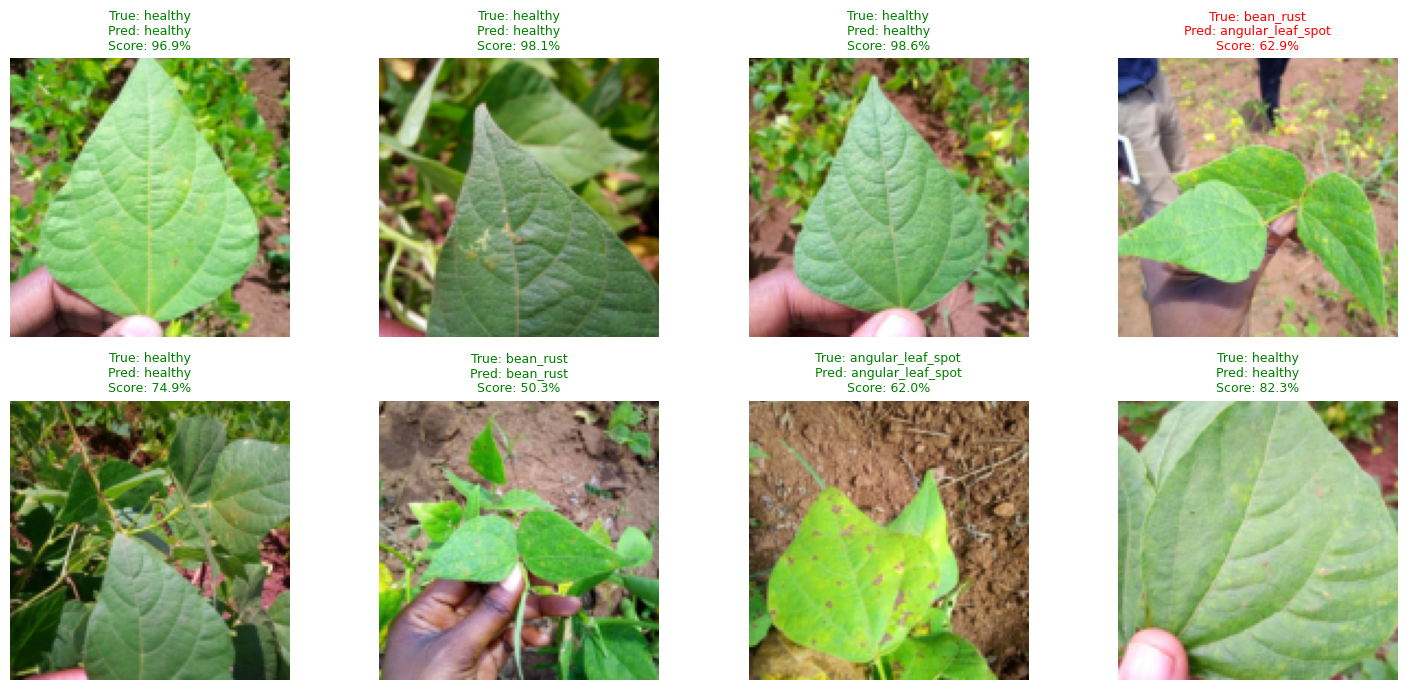

In [53]:
#cell 25
#This uses the reloaded model
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(
    len(test_data), size=8, replace=False
)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))

saved_model.eval()

with torch.no_grad():
    for ax, index in zip(axes.flat, sample_indices):
        image, label = test_data[int(index)]

        logits = saved_model(
            image.unsqueeze(0).to(device)
        )

        probabilities = torch.softmax(logits, dim=1)
        confidence, prediction = probabilities.max(dim=1)

        predicted_index = prediction.item()
        correct = predicted_index == label

        ax.imshow(image.permute(1, 2, 0).numpy())
        ax.set_title(
            f"True: {class_names[label]}\n"
            f"Pred: {class_names[predicted_index]}\n"
            f"Score: {confidence.item() * 100:.1f}%",
            color="green" if correct else "red",
            fontsize=9
        )
        ax.axis("off")

plt.tight_layout()
plt.savefig(output_dir / "prediction_examples.png", dpi=150)
plt.show()

In [54]:
#cell 26 
#saves the class mapping and configuration alongside the weights so my
#preprocessing and settings are documented.
import json

experiment_details = {
    "dataset": "AI-Lab-Makerere/beans",
    "class_names": class_names,
    "image_size": size,
    "batch_size": batch_size,
    "epochs": epoch_number,
    "learning_rate": learning_rate,
    "weight_decay": weight_decay,
    "dropout": dropout_rate,
    "seed": SEED,
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "checkpoint_selection": "lowest validation loss",
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "test_loss": test_loss,
    "test_accuracy": test_acc,
    "pytorch_version": str(torch.__version__)
}

with open(output_dir / "experiment_details.json", "w") as file:
    json.dump(experiment_details, file, indent=2)

print("Experiment settings and results saved.")

Experiment settings and results saved.


In [55]:
#cell 27
#final varification cell
from importlib.metadata import version

required_files = [
    "best_model.pth",
    "training_history.csv",
    "training_curves.png",
    "classification_report.csv",
    "confusion_matrix.png",
    "prediction_examples.png",
    "experiment_details.json"
]

print("Saved-file checks:")

for filename in required_files:
    file_path = output_dir / filename
    assert file_path.exists(), f"Missing file: {filename}"
    assert file_path.stat().st_size > 0, f"Empty file: {filename}"

    print(
        f"{filename}: OK "
        f"({file_path.stat().st_size / 1024:.1f} KiB)"
    )

assert len(true_labels) == len(test_data)
assert cm.sum() == len(test_data)

correct_predictions = int(np.trace(cm))
verified_accuracy = correct_predictions / len(test_data)

assert np.isclose(verified_accuracy, test_acc)

print(f"\nTest images evaluated: {len(true_labels)}")
print(f"Correct predictions: {correct_predictions}")
print(f"Verified accuracy: {verified_accuracy * 100:.2f}%")

packages = [
    "torch",
    "torchvision",
    "datasets",
    "Pillow",
    "numpy",
    "pandas",
    "matplotlib",
    "scikit-learn",
    "torchinfo"
]

environment_text = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
)

(output_dir / "environment_versions.txt").write_text(
    environment_text + "\n"
)

print("\nEnvironment versions recorded.")
print("Final checks passed.")

Saved-file checks:
best_model.pth: OK (1394.6 KiB)
training_history.csv: OK (1.6 KiB)
training_curves.png: OK (130.2 KiB)
classification_report.csv: OK (0.4 KiB)
confusion_matrix.png: OK (44.7 KiB)
prediction_examples.png: OK (510.8 KiB)
experiment_details.json: OK (0.5 KiB)

Test images evaluated: 128
Correct predictions: 108
Verified accuracy: 84.38%

Environment versions recorded.
Final checks passed.


cell 28  
##  Analysis and Discussion

### Overall Training Behaviour

The custom CNN was trained from scratch for 20 epochs using Adam,
cross-entropy loss, a batch size of 32, and a learning rate of 0.001.

Training loss decreased from 1.0936 in epoch 1 to 0.5721 in epoch 20.
Training accuracy increased from 35.01% to 75.82%, indicating that
the model learned useful information from the training images.

Validation performance improved overall but fluctuated between epochs.
For example, validation accuracy was 68.42% at epoch 18 and 78.20%
at epoch 19. Therefore, the final epoch was not automatically selected
as the final model.

### Checkpoint Selection

The checkpoint was selected using the lowest validation loss.

Epoch 19 achieved the lowest validation loss of 0.5079, with validation
accuracy of 78.20%. Although epochs 12 and 16 achieved a slightly higher
validation accuracy of 78.95%, they did not achieve the lowest validation
loss.

The weights saved at epoch 19 were reloaded into a fresh instance of
the same CNN architecture before evaluating the test set.

### Test Performance

The selected model achieved the following results on the held-out
test set:

| Metric | Result |
|---|---:|
| Test images | 128 |
| Correct predictions | 106 |
| Test accuracy | 82.81% |
| Test loss | 0.4617 |
| Macro-average F1-score | 0.8261 |
| Weighted-average F1-score | 0.8254 |

The test set was not used during training or checkpoint selection.

### Class-Level Performance

| Class | Test images | Correct | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|---:|
| Angular leaf spot | 43 | 38 | 0.7600 | 0.8837 | 0.8172 |
| Bean rust | 43 | 29 | 0.8286 | 0.6744 | 0.7436 |
| Healthy | 42 | 39 | 0.9070 | 0.9286 | 0.9176 |

Healthy leaves achieved the strongest performance, with an F1-score
of 0.9176. The model correctly identified 39 of 42 healthy images.

Angular leaf spot achieved high recall of 0.8837, correctly identifying
38 of 43 cases. Its lower precision of 0.7600 indicates that some images
from other classes were also predicted as angular leaf spot.

Bean rust had the lowest recall of 0.6744 and the lowest F1-score
of 0.7436. The model correctly identified 29 of 43 bean-rust images,
making missed bean-rust cases the main class-level weakness.

These metrics do not establish the visual causes of the mistakes.
The confusion matrix and individual misclassified images would need
to be examined to investigate specific error patterns.

### Interpreting Training and Evaluation Metrics

Training metrics were calculated with random augmentation and dropout
active. Validation and test metrics were calculated in evaluation mode,
without random augmentation and with dropout disabled.

These different conditions can contribute to differences between
training and evaluation accuracy. In addition, the test result
uses the epoch-19 checkpoint, whereas the final training accuracy comes
from epoch 20.

Therefore, the final training and test accuracies are not a like-for-like
comparison. The higher test accuracy cannot be attributed to one cause
from this experiment alone.

### Limitations

- The test set contains only 128 images. Each additional correct or
  incorrect prediction changes test accuracy by approximately
  0.78 percentage points.
- Only one architecture and one main hyperparameter configuration
  were evaluated. The chosen settings cannot be claimed to be optimal.
- The dataset's original splits were preserved, but no independent
  duplicate-image audit was performed.
- Performance on an external dataset was not evaluated. Generalization
  to different cameras, environments, or growing conditions has not
  been established.

## 8. Conclusion and Future Work

A custom three-block CNN was implemented and trained from scratch
to classify bean-leaf images into angular leaf spot, bean rust,
and healthy categories.

The project included dataset exploration, preprocessing, training
augmentation, separate training/validation/test loaders, a detailed
architecture summary, training curves, checkpoint saving, and test
evaluation.

The selected checkpoint achieved 82.81% test accuracy and a macro
F1-score of 0.8261. Healthy leaves were classified most successfully,
while bean rust had the lowest recall.

Future work could focus on inspecting misclassified bean-rust images
and comparing lighter augmentation settings. Batch normalization or
a learning-rate scheduler could also be evaluated as separate
experiments.

These proposed changes have not been tested in this project and are
not guaranteed to improve performance. Future model choices should
be based on validation results rather than repeated tuning against
the current test results.

## 9. Code and Dataset References 
### Dataset

- [Beans — Makerere AI Lab](https://huggingface.co/datasets/AI-Lab-Makerere/beans)

### Provided Examples

- [CNN Classification Pipeline — Cat and Dog Example](https://github.com/Rifath-Mahmud/CVPR/blob/main/CNN_Classification_Pipeline(Cat%20and%20Dog%20Example).ipynb)
- [Model Save and Load Example](https://github.com/Rifath-Mahmud/CVPR/blob/main/Model_Save_and_load_Example.ipynb)